# 2D CNN Model

# Ablation Study

Train: preprocessed_augmented_dataset_scaled.csv
Val  : validation_set_scaled.csv
Test : test_set_scaled.csv
Shape: (100000, 5, 4, 1) | Classes: 10

Running variant: 0_baseline_exact
Epoch 1/40
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 18s 8ms/step - accuracy: 0.7331 - loss: 1.3440 - val_accuracy: 0.9375 - val_loss: 0.8128 - learning_rate: 5.0000e-04
Epoch 2/40
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.9189 - loss: 0.9407 - val_accuracy: 0.9500 - val_loss: 0.7296 - learning_rate: 5.0000e-04
Epoch 3/40
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.9468 - loss: 0.8443 - val_accuracy: 0.9656 - val_loss: 0.6878 - learning_rate: 5.0000e-04
Epoch 4/40
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9573 - loss: 0.7972 - val_accuracy: 0.9594 - val_loss: 0.6711 - learning_rate: 5.0000e-04
Epoch 5/40
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.9614 - loss: 0.7684 - val_accuracy: 0.9625 - val_loss: 0.6569 - learning_rate: 5.0000e-04
Epoch 6/40
1563/1563 ━

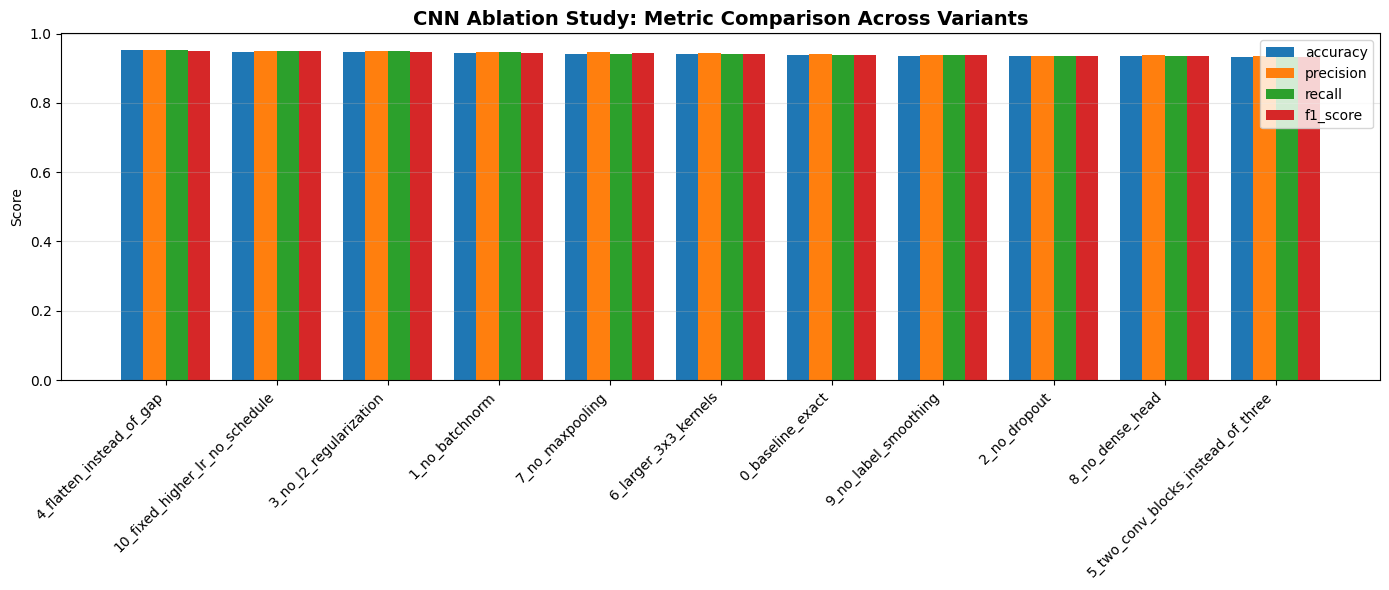

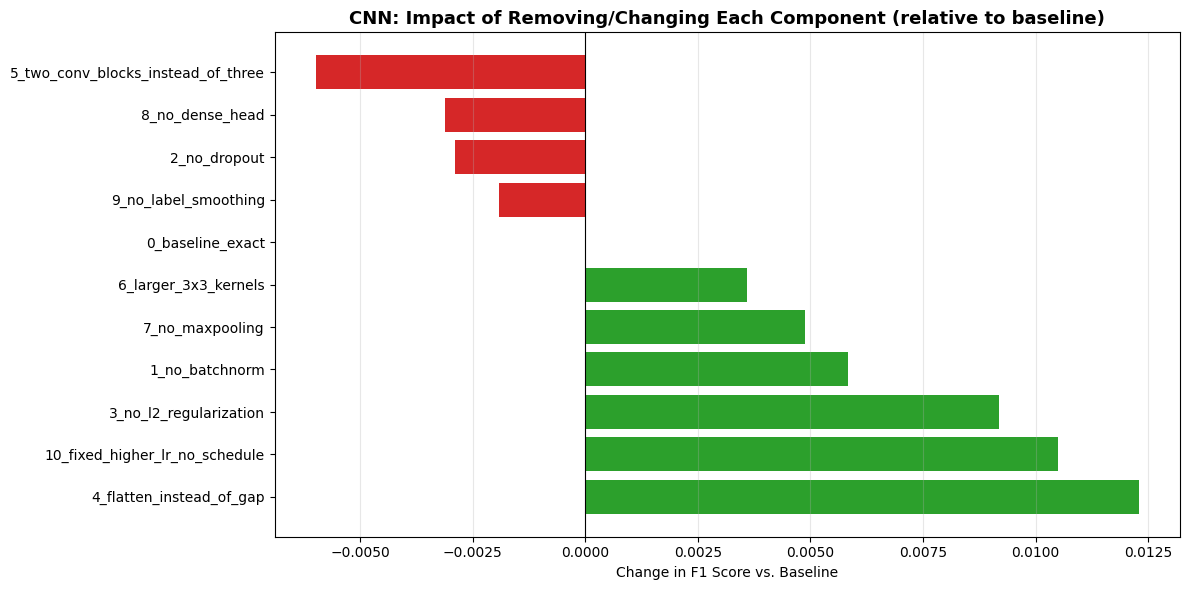

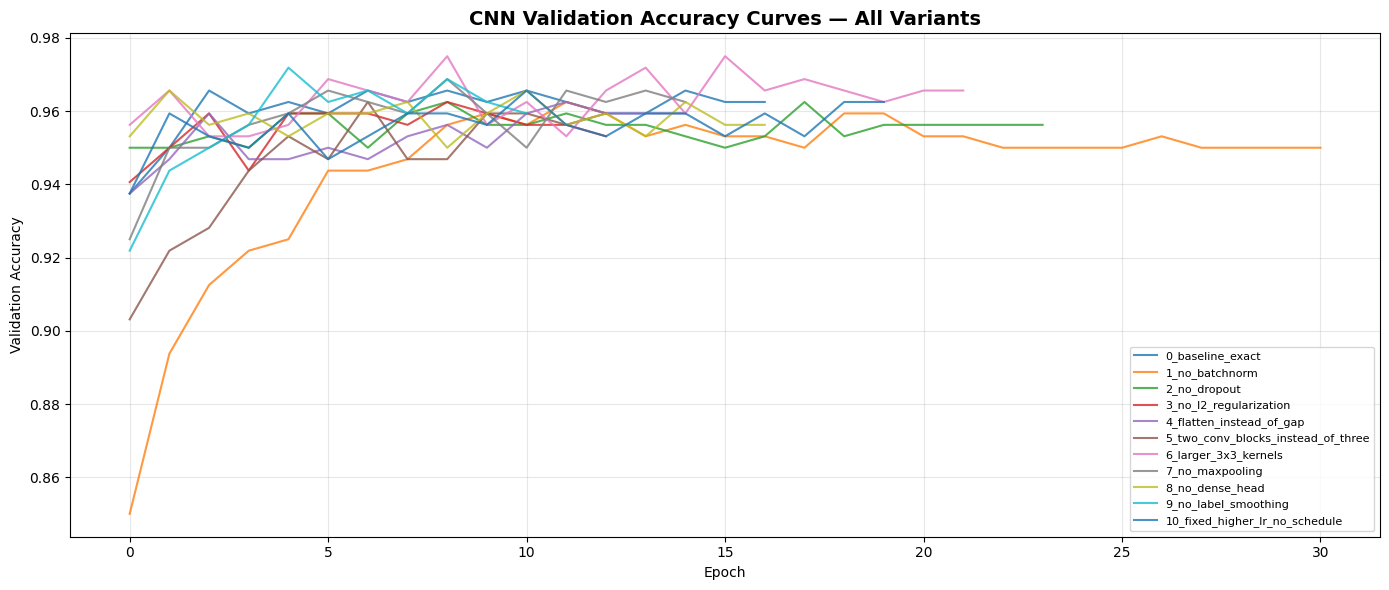


Saved plots: cnn_ablation_metric_comparison.png, cnn_ablation_delta_from_baseline.png, cnn_ablation_val_accuracy_curves.png

SUMMARY: Component impact (F1 delta vs baseline, macro-averaged)
                           variant  f1_delta_vs_baseline  trainable_params
5_two_conv_blocks_instead_of_three             -0.005982              6874
                   8_no_dense_head             -0.003122             11514
                      2_no_dropout             -0.002891             17434
              9_no_label_smoothing             -0.001907             17434
              6_larger_3x3_kernels              0.003586             30314
                   7_no_maxpooling              0.004877             17434
                    1_no_batchnorm              0.005842             16986
            3_no_l2_regularization              0.009191             17434
    10_fixed_higher_lr_no_schedule              0.010494             17434
          4_flatten_instead_of_gap              0.012290   

In [ ]:
# ============================================================
# ABLATION STUDY: 2D CNN FOR BEARING FAULT DETECTION
# Variants tested:
#   0. Full model (baseline)
#   1. No BatchNormalization
#   2. No Dropout
#   3. No L2 regularization
#   4. Flatten layer instead of GlobalAveragePooling2D
#   5. Two Conv blocks instead of three Conv blocks
#   6. Larger convolution kernels (2x2 -> 3x3)
#   7. No MaxPooling layer
#   8. No Dense classification head
#   9. No label smoothing
#   10. Fixed higher learning rate, no ReduceLROnPlateau
# ============================================================

# !pip -q install tensorflow

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Conv2D, BatchNormalization, MaxPooling2D, Dropout,
    GlobalAveragePooling2D, Flatten, Dense, Input
)
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# ============================================================
# LOAD DATA
# ============================================================

def find_file(keyword):
    files_list = os.listdir()
    matches = [f for f in files_list if keyword in f.lower()]
    return matches[0]

train_file = find_file("augmented")
val_file = find_file("validation")
test_file = find_file("test")

print("Train:", train_file)
print("Val  :", val_file)
print("Test :", test_file)

train_df = pd.read_csv(train_file)
val_df = pd.read_csv(val_file)
test_df = pd.read_csv(test_file)

X_train_flat = train_df.iloc[:, :-1].values
y_train_raw = train_df.iloc[:, -1].values

X_val_flat = val_df.iloc[:, :-1].values
y_val_raw = val_df.iloc[:, -1].values

X_test_flat = test_df.iloc[:, :-1].values
y_test_raw = test_df.iloc[:, -1].values

classes = np.unique(y_train_raw)
weights = compute_class_weight(class_weight='balanced', classes=classes, y=y_train_raw)
class_weights = dict(zip(classes, weights))

y_train = to_categorical(y_train_raw)
y_val = to_categorical(y_val_raw)
y_test = to_categorical(y_test_raw)
num_classes = y_train.shape[1]

height = 5
width = 4
padding = (height * width) - X_train_flat.shape[1]

X_train = np.pad(X_train_flat, ((0, 0), (0, padding)), mode='constant')
X_val = np.pad(X_val_flat, ((0, 0), (0, padding)), mode='constant')
X_test = np.pad(X_test_flat, ((0, 0), (0, padding)), mode='constant')

X_train = X_train.reshape((X_train.shape[0], height, width, 1))
X_val = X_val.reshape((X_val.shape[0], height, width, 1))
X_test = X_test.reshape((X_test.shape[0], height, width, 1))

print("Shape:", X_train.shape, "| Classes:", num_classes)


# ============================================================
# CONFIGURABLE MODEL BUILDER
# ============================================================

DEFAULT_CONFIG = {
    "name": "0_baseline_exact",
    "conv_filters": [16, 32, 64],
    "kernel_size": (2, 2),
    "use_batchnorm": True,
    "use_dropout": True,
    "dropout_after_pool": 0.4,       # matches Dropout(0.4) after MaxPool
    "dropout_dense": [0.5, 0.4],     # matches : Dropout(0.5) after Dense(64), Dropout(0.4) after Dense(32)
    "use_l2": True,
    "l2_value": 1e-3,
    "use_maxpool": True,
    "pool_after_block": 1,           # pool after 2nd conv block (index 1),
    "pooling_type": "gap",           # "gap" or "flatten"
    "use_dense_head": True,
    "dense_units": [64, 32],
    "use_class_weights": True,
    "learning_rate": 5e-4,
    "use_lr_schedule": True,
    "lr_factor": 0.3,
    "lr_patience": 3,
    "early_stop_patience": 6,
    "label_smoothing": 0.1,
    "metric_average": "macro",
}


def reg(cfg):
    return l2(cfg["l2_value"]) if cfg["use_l2"] else None


def build_model(cfg):
    inputs = Input(shape=(height, width, 1))
    x = inputs

    for i, filters in enumerate(cfg["conv_filters"]):
        x = Conv2D(filters, cfg["kernel_size"], padding='same',
                   activation='relu', kernel_regularizer=reg(cfg))(x)
        if cfg["use_batchnorm"]:
            x = BatchNormalization()(x)
        if cfg["use_maxpool"] and i == cfg["pool_after_block"]:
            x = MaxPooling2D((2, 2))(x)
        if cfg["use_dropout"] and i == cfg["pool_after_block"]:
            x = Dropout(cfg["dropout_after_pool"])(x)

    if cfg["pooling_type"] == "gap":
        x = GlobalAveragePooling2D()(x)
    else:
        x = Flatten()(x)

    if cfg["use_dense_head"]:
        for units, drop_rate in zip(cfg["dense_units"], cfg["dropout_dense"]):
            x = Dense(units, activation='relu', kernel_regularizer=reg(cfg))(x)
            if cfg["use_dropout"]:
                x = Dropout(drop_rate)(x)

    outputs = Dense(num_classes, activation='softmax')(x)

    model = Model(inputs, outputs)
    loss = tf.keras.losses.CategoricalCrossentropy(label_smoothing=cfg["label_smoothing"])
    model.compile(
        optimizer=Adam(learning_rate=cfg["learning_rate"]),
        loss=loss,
        metrics=['accuracy'],
    )
    return model


def get_callbacks(cfg):
    callbacks = [EarlyStopping(monitor='val_loss', patience=cfg["early_stop_patience"],
                                restore_best_weights=True)]
    if cfg["use_lr_schedule"]:
        callbacks.append(ReduceLROnPlateau(monitor='val_loss', factor=cfg["lr_factor"],
                                            patience=cfg["lr_patience"], min_lr=1e-6))
    return callbacks


def run_experiment(cfg, epochs=80, batch_size=64, verbose=0):
    tf.keras.backend.clear_session()
    tf.random.set_seed(SEED)

    model = build_model(cfg)
    cw = class_weights if cfg["use_class_weights"] else None

    history = model.fit(
        X_train, y_train,
        epochs=epochs,
        batch_size=batch_size,
        validation_data=(X_val, y_val),
        callbacks=get_callbacks(cfg),
        class_weight=cw,
        verbose=verbose,
    )

    y_pred = model.predict(X_test, verbose=0)
    y_pred_classes = np.argmax(y_pred, axis=1)
    avg = cfg["metric_average"]

    metrics = {
        "variant": cfg["name"],
        "accuracy": accuracy_score(y_test_raw, y_pred_classes),
        "precision": precision_score(y_test_raw, y_pred_classes, average=avg, zero_division=0),
        "recall": recall_score(y_test_raw, y_pred_classes, average=avg, zero_division=0),
        "f1_score": f1_score(y_test_raw, y_pred_classes, average=avg, zero_division=0),
        "epochs_run": len(history.history['accuracy']),
        "final_val_accuracy": history.history['val_accuracy'][-1],
        "final_val_loss": history.history['val_loss'][-1],
        "trainable_params": model.count_params(),
    }
    return metrics, history


# ============================================================
# DEFINE ABLATION VARIANTS
# ============================================================

def make_cfg(overrides):
    cfg = dict(DEFAULT_CONFIG)
    cfg.update(overrides)
    return cfg


ablation_variants = [
    make_cfg({"name": "0_baseline_exact"}),

    make_cfg({"name": "1_no_batchnorm", "use_batchnorm": False}),

    make_cfg({"name": "2_no_dropout", "use_dropout": False}),

    make_cfg({"name": "3_no_l2_regularization", "use_l2": False}),

    make_cfg({"name": "4_flatten_instead_of_gap", "pooling_type": "flatten"}),

    make_cfg({
        "name": "5_two_conv_blocks_instead_of_three",
        "conv_filters": [16, 32],
        "pool_after_block": 1,
    }),

    make_cfg({"name": "6_larger_3x3_kernels", "kernel_size": (3, 3)}),

    make_cfg({"name": "7_no_maxpooling", "use_maxpool": False}),

    make_cfg({"name": "8_no_dense_head", "use_dense_head": False}),

    make_cfg({"name": "9_no_label_smoothing", "label_smoothing": 0.0}),

    make_cfg({
        "name": "10_fixed_higher_lr_no_schedule",
        "learning_rate": 2.5e-3,
        "use_lr_schedule": False,
    }),
]


# ============================================================
# RUN ALL EXPERIMENTS
# ============================================================
# NOTE: epochs=80 matches the original script but will make 11 full
# training runs slow. Consider epochs=30-40 for a faster first pass;
# EarlyStopping will still cut short unproductive runs either way.

EPOCHS = 40  # reduce from the original 80 for a faster ablation sweep;
             # bump back to 80 for a final, publication-grade run

results = []
histories = {}

for cfg in ablation_variants:
    print("\n" + "=" * 70)
    print(f"Running variant: {cfg['name']}")
    print("=" * 70)
    metrics, history = run_experiment(cfg, epochs=EPOCHS, batch_size=64, verbose=1)
    results.append(metrics)
    histories[cfg["name"]] = history.history
    print(f"  -> Accuracy: {metrics['accuracy']:.4f} | F1: {metrics['f1_score']:.4f} "
          f"| Epochs: {metrics['epochs_run']} | Params: {metrics['trainable_params']:,}")

results_df = pd.DataFrame(results).sort_values("f1_score", ascending=False).reset_index(drop=True)

print("\n" + "=" * 70)
print("ABLATION STUDY RESULTS (sorted by F1 score, macro-averaged)")
print("=" * 70)
print(results_df.to_string(index=False))

results_df.to_csv("cnn_ablation_results.csv", index=False)
with open("cnn_ablation_histories.json", "w") as f:
    json.dump(histories, f)

print("\nSaved: cnn_ablation_results.csv, cnn_ablation_histories.json")


# ============================================================
# VISUALIZATIONS
# ============================================================

baseline_row = results_df[results_df["variant"] == "0_baseline_exact"].iloc[0]

plt.figure(figsize=(14, 6))
metrics_to_plot = ["accuracy", "precision", "recall", "f1_score"]
x = np.arange(len(results_df))
width = 0.2
for i, metric in enumerate(metrics_to_plot):
    plt.bar(x + i * width, results_df[metric], width, label=metric)
plt.xticks(x + width * 1.5, results_df["variant"], rotation=45, ha='right')
plt.ylabel("Score")
plt.title("CNN Ablation Study: Metric Comparison Across Variants", fontsize=14, fontweight='bold')
plt.legend()
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig("cnn_ablation_metric_comparison.png", dpi=150)
plt.show()

plt.figure(figsize=(12, 6))
delta_f1 = results_df["f1_score"] - baseline_row["f1_score"]
colors = ['#d62728' if v < 0 else '#2ca02c' for v in delta_f1]
plt.barh(results_df["variant"], delta_f1, color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel("Change in F1 Score vs. Baseline")
plt.title("CNN: Impact of Removing/Changing Each Component (relative to baseline)",
          fontsize=13, fontweight='bold')
plt.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig("cnn_ablation_delta_from_baseline.png", dpi=150)
plt.show()

plt.figure(figsize=(14, 6))
for name, hist in histories.items():
    plt.plot(hist['val_accuracy'], label=name, alpha=0.8)
plt.title("CNN Validation Accuracy Curves — All Variants", fontsize=14, fontweight='bold')
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend(fontsize=8, loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("cnn_ablation_val_accuracy_curves.png", dpi=150)
plt.show()

print("\nSaved plots: cnn_ablation_metric_comparison.png, "
      "cnn_ablation_delta_from_baseline.png, cnn_ablation_val_accuracy_curves.png")

# ============================================================
# SUMMARY
# ============================================================
print("\n" + "=" * 70)
print("SUMMARY: Component impact (F1 delta vs baseline, macro-averaged)")
print("=" * 70)
summary = results_df.copy()
summary["f1_delta_vs_baseline"] = summary["f1_score"] - baseline_row["f1_score"]
summary = summary[summary["variant"] != "0_baseline_exact"]
summary = summary.sort_values("f1_delta_vs_baseline")
print(summary[["variant", "f1_delta_vs_baseline", "trainable_params"]].to_string(index=False))